In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Import data

In [2]:
data = pd.read_csv("C:/Coursera/ecommerce-business-analytics/data/ecommerce_sales_analytics_5000.csv")

### Data cleaning and preparation

1. Size of the data(rows and columns)
2. Missing values
3. Data type of the columns
4. Duplicate values
5. Invalid/Impossible values
6. Inconsistent Categorical values
7. Outliers

In [3]:
data.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [4]:
#Size of the data
data.shape

(5000, 12)

In [5]:
#Columns in the data 
data.columns

Index(['order_id', 'order_date', 'customer_id', 'product_category', 'region',
       'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days',
       'customer_rating', 'revenue'],
      dtype='object')

In [6]:
#Missing values
data.isna().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

In [7]:
#Data type of the columns
data.dtypes

order_id              int64
order_date           object
customer_id           int64
product_category     object
region               object
quantity              int64
unit_price          float64
discount            float64
payment_method       object
delivery_days         int64
customer_rating     float64
revenue             float64
dtype: object

In [8]:
data['order_date'] = pd.to_datetime(data['order_date'])

In [9]:
data.dtypes

order_id                     int64
order_date          datetime64[ns]
customer_id                  int64
product_category            object
region                      object
quantity                     int64
unit_price                 float64
discount                   float64
payment_method              object
delivery_days                int64
customer_rating            float64
revenue                    float64
dtype: object

In [10]:
#Duplicate values
data.duplicated().sum()

np.int64(0)

In [11]:
#Invalid/Impossible values
data.describe()

,order_id,order_date,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,2028-11-04 12:00:00,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
min,10001.000000,2022-01-01 00:00:00,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,2025-06-03 18:00:00,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,2028-11-04 12:00:00,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,2032-04-07 06:00:00,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,2035-09-09 00:00:00,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000
std,1443.520003,NaN,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219


In [12]:
#Inconsistant categorical value 
data['product_category'].value_counts()

product_category
Electronics    1777
Clothing       1531
Home            969
Beauty          723
Name: count, dtype: int64

In [13]:
data['payment_method'].value_counts()

payment_method
Card      2270
COD       1774
Wallet     956
Name: count, dtype: int64

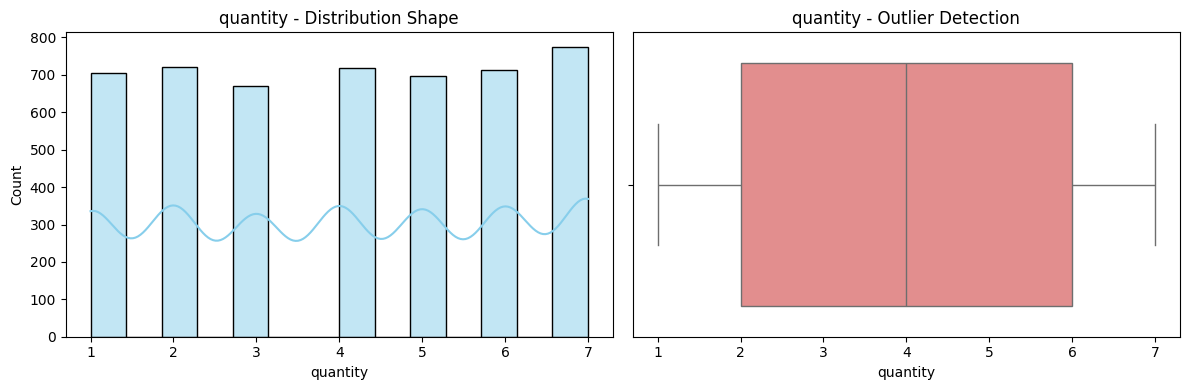

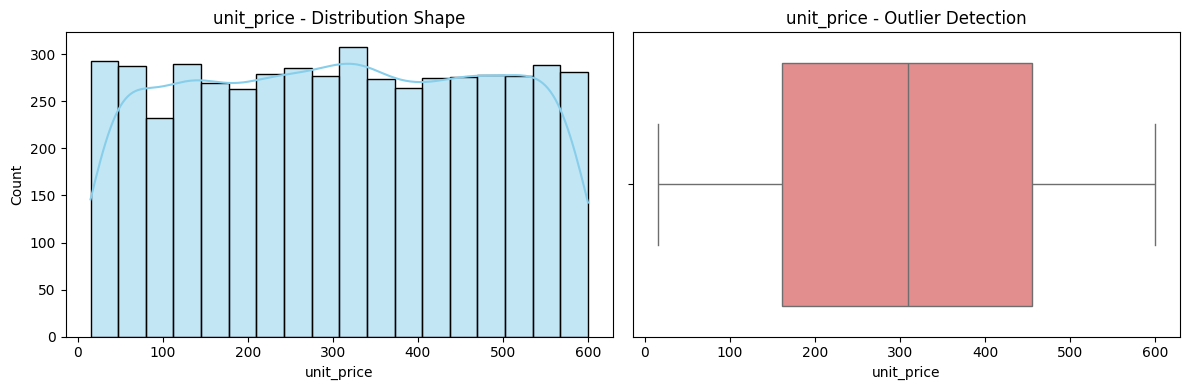

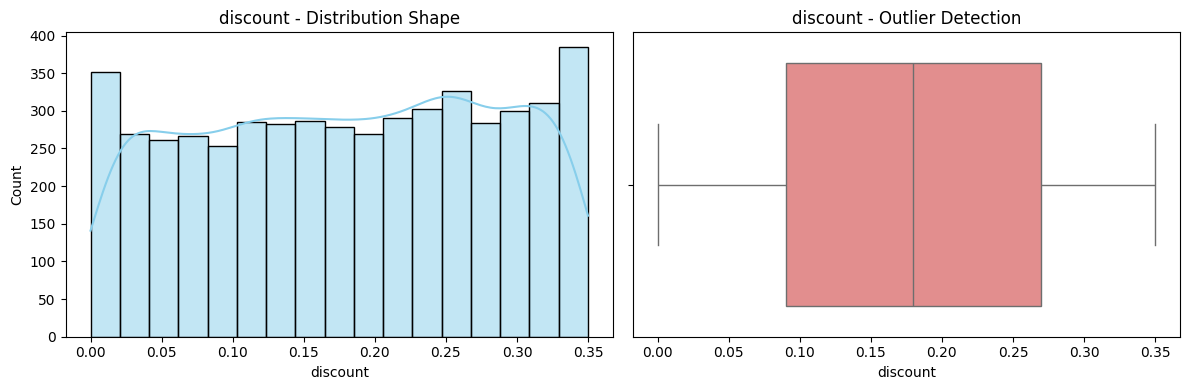

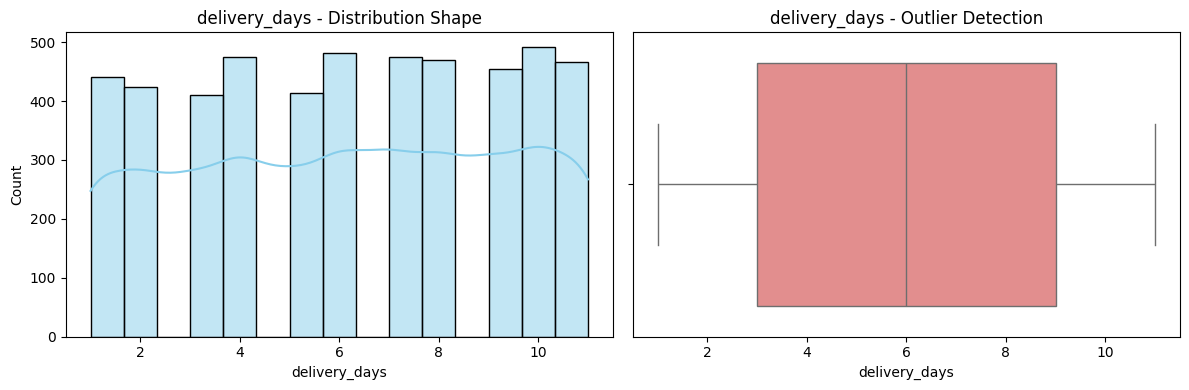

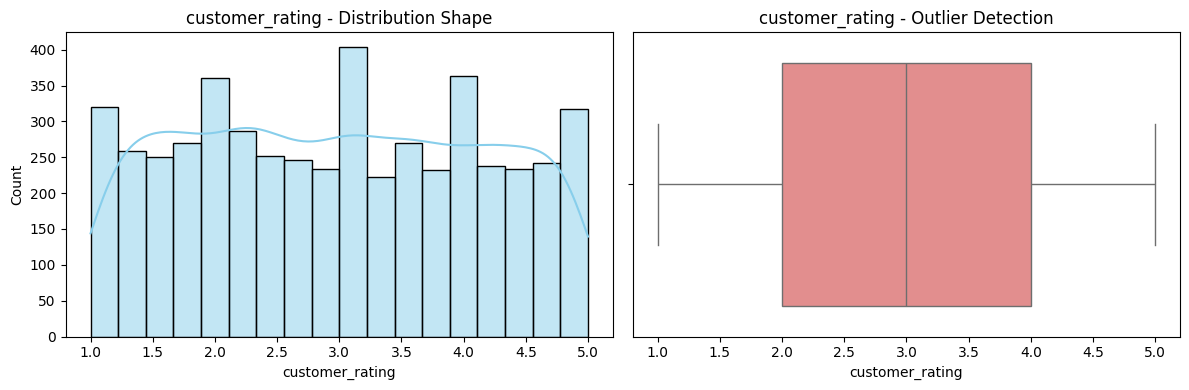

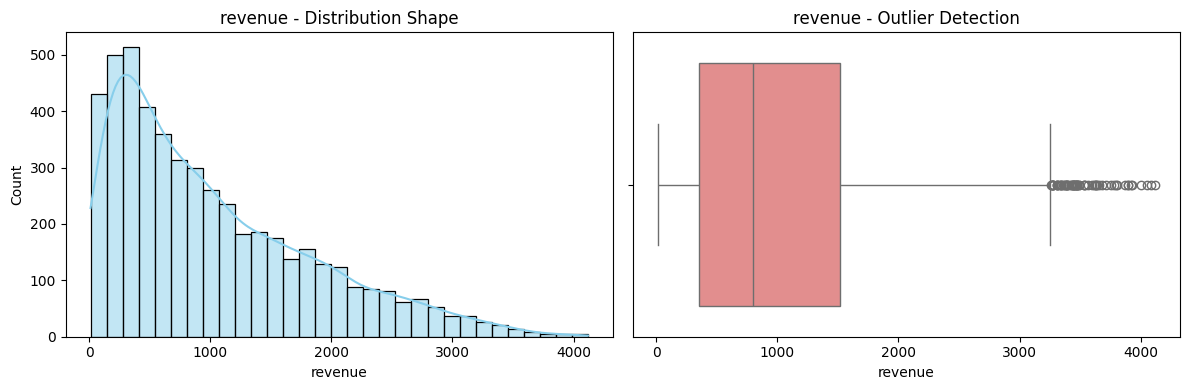

In [18]:
#Outliers
numeric_cols = data.select_dtypes(include=['int64', 'float64']).columns
cols_to_ignore = ['order_id', 'customer_id']
cols_to_plot = numeric_cols.drop(cols_to_ignore, errors='ignore')

for col in cols_to_plot:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    sns.histplot(data=data, x=col, kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(col + ' - Distribution Shape')
    
    sns.boxplot(data=data, x=col, ax=axes[1], color='lightcoral')
    axes[1].set_title(col + ' - Outlier Detection')
    
    plt.tight_layout()
    plt.show()